# 03 · Experiment A: fusing the 8 sensors of S1 (RQ2)

Each sensor is treated as a separate source, and we ask at which level combining them works best.

| Level | What is combined | Our implementation |
|---|---|---|
| Low (A1) | raw curves | (a) flatten 8 × 300 conductance values → scaler → PCA(10) → classifier; (b) 8-channel 1D-CNN |
| Mid (A2) | features | 15 features per sensor (baseline, extrema, ΔG, slopes, area, timing, FFT, …) → 120 values → classifier |
| High (A3) | decisions | one classifier per sensor → majority vote / mean probability / weighted mean / stacking |

**Leakage control.** Features are computed per recording. Every fitted step (scaler, PCA, SVM grid search, combiner weights, stacking meta-learner) is fitted on the training fold only; the weights and the meta-learner use a 5-fold *inner* CV inside the training fold. Code: `src/experiments/expA_s1_fusion.py`.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30); pd.set_option('display.precision', 3)
R = ROOT / 'results'; F = R / 'figures'; A = R / 'ablations'
def show(p, w=650):
    p = Path(p)
    display(Image(filename=str(p), width=w)) if p.exists() else print('missing figure:', p.name)
def table(p, **kw):
    p = Path(p)
    return pd.read_csv(p, **kw) if p.exists() else print('missing table:', p.name)

In [2]:
a = table(R / 'expA_fusion_levels.csv')
a[a.scheme == 'rskf5'].sort_values('accuracy_mean', ascending=False).head(15)

,exp,level,variant,scheme,n_repeats,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std
18,expA_main,low,A1a|LR,rskf5,10,0.917,0.021,0.899,0.016,0.896,0.020
19,expA_main,low,A1a|SVM,rskf5,10,0.910,0.024,0.879,0.028,0.896,0.022
39,expA_cnn_win,low,A1b|CNN+win,rskf5,10,0.891,0.022,0.863,0.024,0.867,0.026
37,expA_cnn,low,A1b|CNN,rskf5,10,0.888,0.032,0.872,0.030,0.867,0.035
24,expA_main,mid,A2|SVM,rskf5,10,0.867,0.022,0.811,0.023,0.830,0.022
27,expA_main,mid,A2|MLP,rskf5,10,0.866,0.031,0.840,0.040,0.840,0.040
22,expA_main,low,A1a|MLP,rskf5,10,0.850,0.048,0.835,0.042,0.829,0.047
23,expA_main,mid,A2|LR,rskf5,10,0.847,0.021,0.816,0.035,0.817,0.027
20,expA_main,low,A1a|RF,rskf5,10,0.845,0.027,0.817,0.021,0.825,0.026
35,expA_main,high,A3|SVM|stacking,rskf5,10,0.843,0.029,0.788,0.039,0.796,0.037


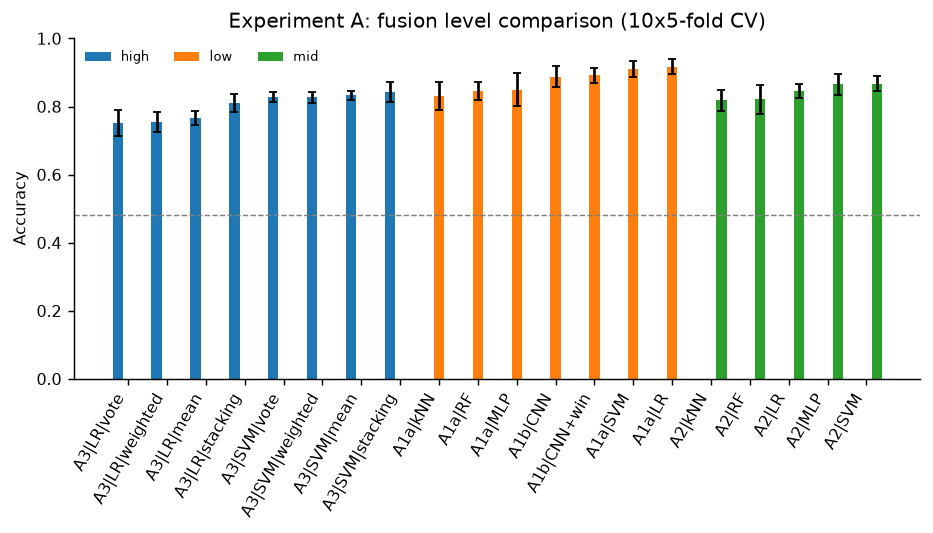

In [3]:
show(F / 'expA_fusion_levels.png', 900)

## Best model per level and paired tests
Wilcoxon signed-rank on the 10 per-repeat accuracies of 5-fold CV; McNemar's test on the LOO predictions.

In [4]:
table(R / 'expA_significance.csv')

,A,B,acc_A_rskf,acc_B_rskf,wilcoxon_p_rskf,loo_A_only_correct,loo_B_only_correct,mcnemar_p_loo
0,A1a|LR,A2|SVM,0.917,0.867,0.002,4,2,0.688
1,A1a|LR,A3|SVM|stacking,0.917,0.843,0.002,5,1,0.219
2,A2|SVM,A3|SVM|stacking,0.867,0.843,0.250,2,0,0.500


## LOO numbers (for comparison with the paper's validation scheme)

In [5]:
a[a.scheme == 'loo'].sort_values('accuracy_mean', ascending=False).head(10)

,exp,level,variant,scheme,n_repeats,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std
1,expA_main,low,A1a|SVM,loo,1,0.948,0.0,0.921,0.0,0.935,0.0
0,expA_main,low,A1a|LR,loo,1,0.931,0.0,0.910,0.0,0.907,0.0
38,expA_cnn_win,low,A1b|CNN+win,loo,1,0.931,0.0,0.910,0.0,0.915,0.0
36,expA_cnn,low,A1b|CNN,loo,1,0.914,0.0,0.876,0.0,0.883,0.0
6,expA_main,mid,A2|SVM,loo,1,0.897,0.0,0.843,0.0,0.857,0.0
5,expA_main,mid,A2|LR,loo,1,0.879,0.0,0.852,0.0,0.859,0.0
17,expA_main,high,A3|SVM|stacking,loo,1,0.862,0.0,0.798,0.0,0.806,0.0
3,expA_main,low,A1a|kNN,loo,1,0.845,0.0,0.850,0.0,0.830,0.0
14,expA_main,high,A3|SVM|vote,loo,1,0.845,0.0,0.776,0.0,0.804,0.0
15,expA_main,high,A3|SVM|mean,loo,1,0.845,0.0,0.776,0.0,0.804,0.0
